# Getting started with iAWE

In 2013, the iAWE team measured electricity, water, light, temperature and motion in one home in New Delhi. This notebook uses three files from the [official Zenodo release v1.0.0](https://doi.org/10.5281/zenodo.24361973).

- Count motion detections by hour of the day.
- Plot a week of light and temperature for one sensor.
- Compare circuit measurements with two annotated switching events.

Run the cells from top to bottom. The downloads total about **17 MB** and are saved in the local `iawe-data/` folder. Colab has the required libraries. For local Jupyter, use Python 3.11 or later with `python -m pip install jupyterlab pandas matplotlib`.

In [1]:
from hashlib import file_digest
from io import StringIO
from pathlib import Path
from shutil import copyfileobj
from tempfile import NamedTemporaryFile
from urllib.request import Request, urlopen
from zoneinfo import ZoneInfo

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

IST = ZoneInfo("Asia/Kolkata")
RED, BLUE, GREEN = "#ad3328", "#245f7c", "#39634e"
plt.rcParams.update({
    "figure.dpi": 115,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.axisbelow": True,
    "font.size": 11,
    "grid.alpha": 0.22,
})

## Download from Zenodo

The file URLs and SHA-256 checksums are pinned to v1.0.0. If you already downloaded these files from the record, put them in `iawe-data/` with their original names. The notebook checks them before use.

In [2]:
RECORD = "https://zenodo.org/api/records/24361973/files"
DATA_DIR = Path("iawe-data")
DATA_DIR.mkdir(exist_ok=True)
CHECKSUMS = {
    "pir.csv.gz": "e281f960474b44a073adb4b9ee1a0f51244638d5c1144abf2c62b8f91b9b4ada",
    "light_temp.csv.gz": "e4f5e67576add065ea303c85039d7032adda3f640b2871dfc1652944bb2fbb98",
    "ct_data_controlled.csv": "76d28f9407516aa4bd8ae70bff5bde5f4b67edaa55c1439fc2be32243f3a0354",
}


def sha256(path):
    with path.open("rb") as source:
        return file_digest(source, "sha256").hexdigest()


def zenodo_file(name):
    destination = DATA_DIR / name
    expected = CHECKSUMS[name]
    if destination.is_file() and sha256(destination) == expected:
        print(f"Verified cached file: {name}")
        return destination

    request = Request(f"{RECORD}/{name}/content", headers={"User-Agent": "iAWE-Quickstart/1.0"})
    temporary = NamedTemporaryFile(dir=DATA_DIR, suffix=".part", delete=False)
    partial = Path(temporary.name)
    try:
        with temporary, urlopen(request, timeout=60) as response:
            copyfileobj(response, temporary)
        if sha256(partial) != expected:
            raise ValueError(f"Checksum mismatch for {name}. Run this cell again to retry.")
        partial.replace(destination)
    finally:
        partial.unlink(missing_ok=True)

    print(f"Downloaded and verified: {name}")
    return destination


motion_file = zenodo_file("pir.csv.gz")
ambient_file = zenodo_file("light_temp.csv.gz")
circuit_file = zenodo_file("ct_data_controlled.csv")

Downloaded and verified: pir.csv.gz


Downloaded and verified: light_temp.csv.gz


Downloaded and verified: ct_data_controlled.csv


## When did the motion sensors record events?

Count detections across sensor nodes by local hour. The file contains some implausible timestamps, so keep records from 2013 only. These counts describe sensor detections. They cannot estimate the number of people in a room or how long someone stayed there.

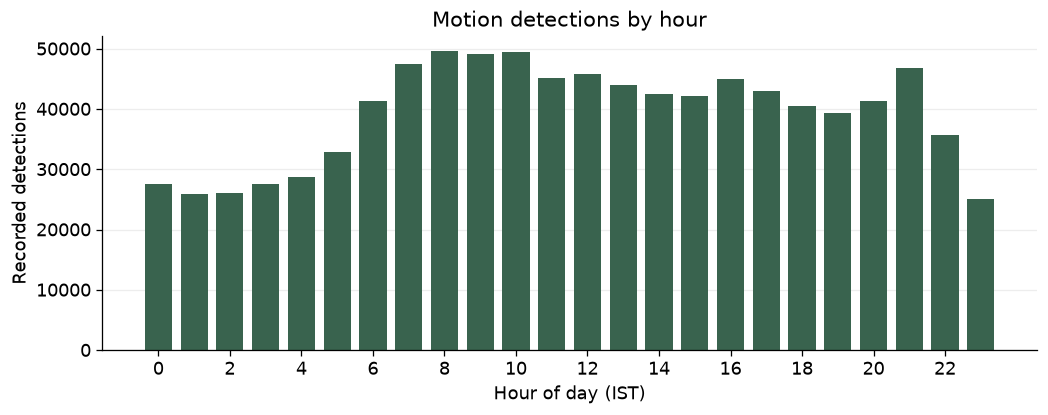

2013 records counted: 941,524


In [3]:
def local_time(values):
    return pd.to_datetime(values, unit="s", utc=True, errors="coerce").dt.tz_convert(IST)


hourly_motion = pd.Series(0, index=range(24), dtype="int64")
for chunk in pd.read_csv(motion_file, usecols=["timestamp"], chunksize=250_000):
    time = local_time(chunk["timestamp"])
    counts = time[time.dt.year.eq(2013)].dt.hour.value_counts()
    hourly_motion += counts.reindex(hourly_motion.index, fill_value=0)

fig, ax = plt.subplots(figsize=(9, 3.5), layout="constrained")
ax.bar(hourly_motion.index, hourly_motion, color=GREEN, width=0.76)
ax.set(
    title="Motion detections by hour",
    xlabel="Hour of day (IST)",
    ylabel="Recorded detections",
    xticks=range(0, 24, 2),
)
ax.grid(axis="y")
plt.show()

print(f"2013 records counted: {hourly_motion.sum():,}")

## How do light and temperature change over a week?

Look at July 13 to 19, 2013, using the sensor node with the most readings in that window. Take the hourly median to make the two series easier to read. Light uses the device's 0 to 100 scale. The temperature column is in Fahrenheit. Hours without observations stay blank.

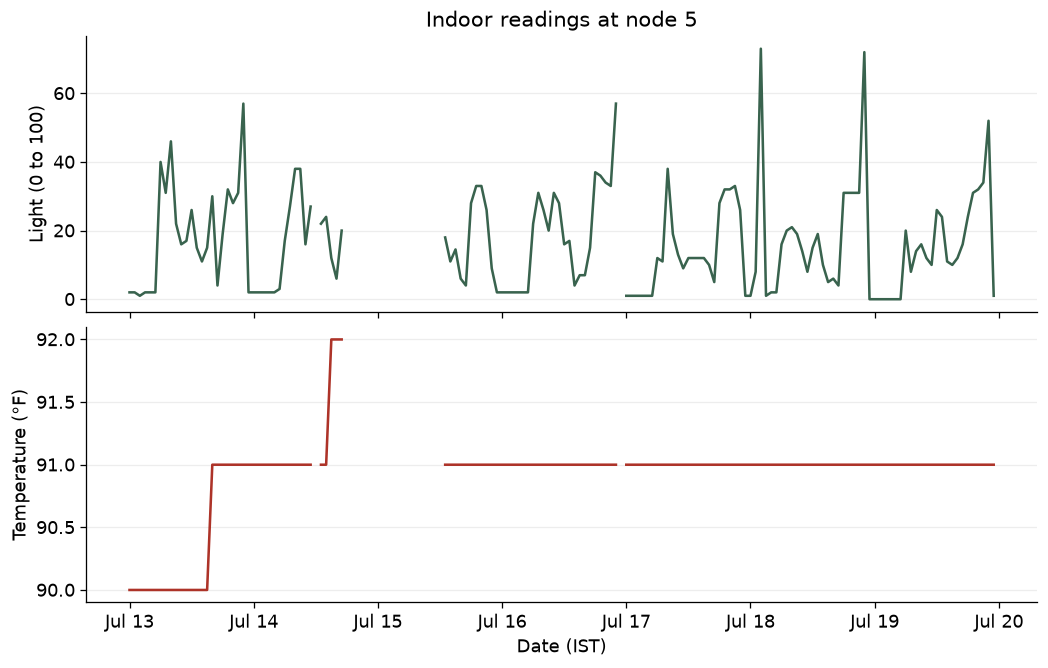

Node 5: 177,149 rows. 21 of 168 hours have no temperature reading.


In [4]:
start = pd.Timestamp("2013-07-13", tz=IST)
end = pd.Timestamp("2013-07-20", tz=IST)
samples = []

for chunk in pd.read_csv(ambient_file, dtype={"light": "string", "temp": "string"}, chunksize=250_000):
    time = local_time(chunk["timestamp"])
    in_week = time.ge(start) & time.lt(end)
    samples.append(chunk.loc[in_week, ["node_id", "light", "temp"]].assign(time=time[in_week]))

week = pd.concat(samples, ignore_index=True)
for column in ("light", "temp"):
    week[column] = pd.to_numeric(week[column], errors="coerce")
node = week["node_id"].value_counts().idxmax()
measurements = week.loc[week["node_id"].eq(node), ["time", "light", "temp"]]
hourly = measurements.set_index("time").resample("h").median()
hourly = hourly.reindex(pd.date_range(start, end, freq="h", inclusive="left"))

fig, (light_ax, temp_ax) = plt.subplots(2, 1, sharex=True, figsize=(9, 5.7), layout="constrained")
light_ax.plot(hourly.index, hourly["light"], color=GREEN, linewidth=1.6)
light_ax.set(title=f"Indoor readings at node {node}", ylabel="Light (0 to 100)")
temp_ax.plot(hourly.index, hourly["temp"], color=RED, linewidth=1.6)
temp_ax.set(xlabel="Date (IST)", ylabel="Temperature (°F)")
temp_ax.xaxis.set_major_locator(mdates.DayLocator(tz=IST))
temp_ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d", tz=IST))
for ax in (light_ax, temp_ax):
    ax.grid(axis="y")
plt.show()

missing_hours = hourly["temp"].isna().sum()
print(f"Node {node}: {len(measurements):,} rows. {missing_hours} of {len(hourly)} hours have no temperature reading.")

## What do the circuits record when an appliance switches?

On August 4, the team [logged controlled switching events](https://github.com/nipunbatra/Home_Deployment/blob/master/dataset/Readme.md) in IST. The log records the iron turning on at 12:21 and off at 12:25. Plot the measurements around those times to see which circuits change.

The trace is a headerless CSV. Read it as Unix timestamp, channel and reading. Strip legacy NUL bytes in memory and skip rows with missing or invalid fields. Channel numbers are the IDs in this trace. The annotations identify the appliance and time, so use the deployment metadata before assigning an appliance to a particular channel.

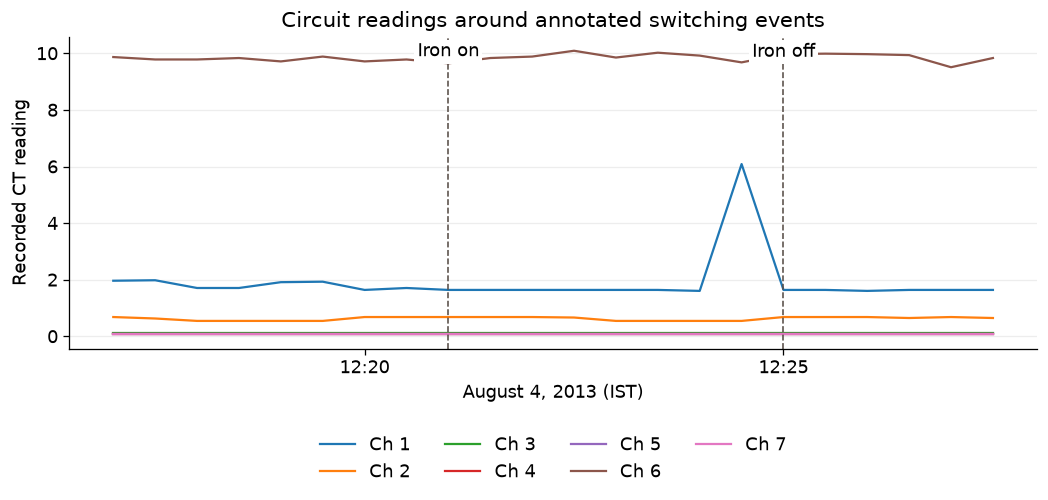

Plotted 7 channels. 3 malformed rows excluded from the trace.


In [5]:
cleaned = circuit_file.read_bytes().replace(b"\0", b"").decode("utf-8")
trace = pd.read_csv(StringIO(cleaned), header=None, names=["timestamp", "channel", "reading"])
for column in ("timestamp", "channel", "reading"):
    trace[column] = pd.to_numeric(trace[column], errors="coerce")

complete = trace.dropna()
complete = complete.assign(time=local_time(complete["timestamp"]))
start = pd.Timestamp("2013-08-04 12:17", tz=IST)
end = pd.Timestamp("2013-08-04 12:28", tz=IST)
window = complete.loc[complete["time"].ge(start) & complete["time"].lt(end)]
channels = window.pivot_table(index="time", columns="channel", values="reading", aggfunc="median")
channels = channels.resample("30s").median()

fig, ax = plt.subplots(figsize=(9, 4.2), layout="constrained")
for channel in channels:
    ax.plot(channels.index, channels[channel], label=f"Ch {int(channel)}", linewidth=1.4)

for time, label in [("12:21", "Iron on"), ("12:25", "Iron off")]:
    event = pd.Timestamp(f"2013-08-04 {time}", tz=IST)
    ax.axvline(event, color="#574d47", linestyle="--", linewidth=1)
    ax.text(event, 0.98, label, transform=ax.get_xaxis_transform(), ha="center", va="top",
            bbox={"facecolor": "white", "edgecolor": "none", "pad": 2})

ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=IST))
ax.set(title="Circuit readings around annotated switching events",
       xlabel="August 4, 2013 (IST)", ylabel="Recorded CT reading")
ax.grid(axis="y")
ax.legend(ncols=4, loc="upper center", bbox_to_anchor=(0.5, -0.23), frameon=False)
plt.show()

print(f"Plotted {len(channels.columns)} channels. {len(trace) - len(complete)} malformed rows excluded from the trace.")

## Use other files from the release

- For appliance-level energy analysis, use `electricity.tar.gz`. The labels file maps meter numbers to appliances. Align mains channels 1 and 2 in time before summing active power.
- For water supply timing, look at the pulse-state records by meter. Review repeated and invalid states before interpreting events. Estimating volume requires a validated calibration.
- The [release record](https://doi.org/10.5281/zenodo.24361973) includes a data dictionary, a quickstart for the main electricity archive and file checksums.

Cite both the [2013 BuildSys paper](https://doi.org/10.1145/2528282.2528293) and the [versioned Zenodo dataset](https://doi.org/10.5281/zenodo.24361973) if you use iAWE. The data are licensed under [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).